         date      price  bedrooms  bathrooms  sqft_living  sqft_lot  floors  \
0  2014-05-02   313000.0       3.0       1.50         1340      7912     1.5   
1  2014-05-02  2384000.0       5.0       2.50         3650      9050     2.0   
2  2014-05-02   342000.0       3.0       2.00         1930     11947     1.0   
3  2014-05-02   420000.0       3.0       2.25         2000      8030     1.0   
4  2014-05-02   550000.0       4.0       2.50         1940     10500     1.0   

   waterfront  view  condition  sqft_above  sqft_basement  yr_built  \
0           0     0          3        1340              0      1955   
1           0     4          5        3370            280      1921   
2           0     0          4        1930              0      1966   
3           0     0          4        1000           1000      1963   
4           0     0          4        1140            800      1976   

   yr_renovated                    street       city  statezip  price_per_sqft  
0          

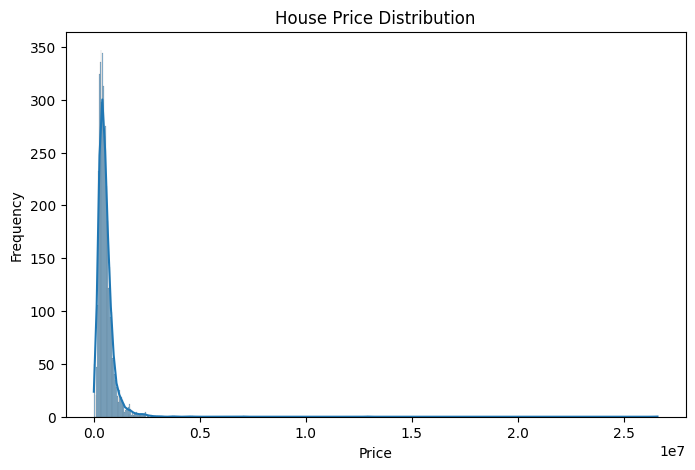

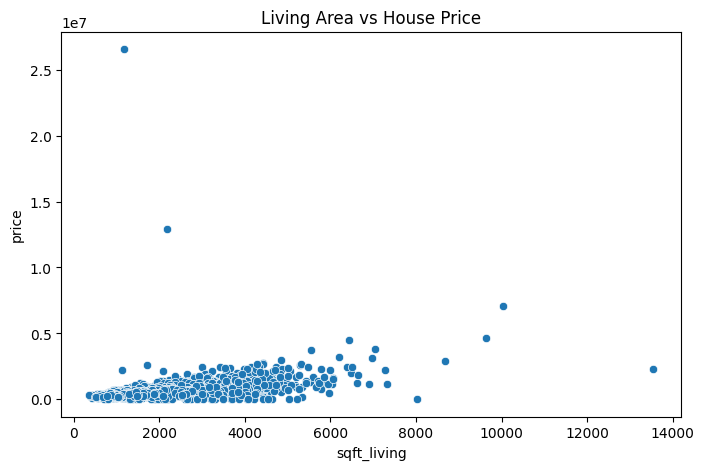

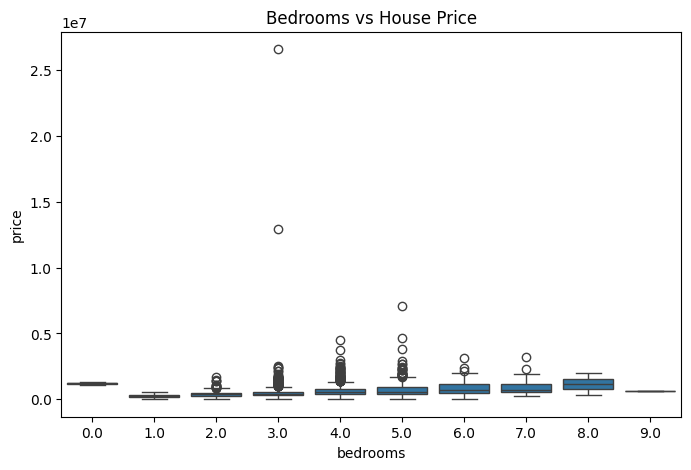

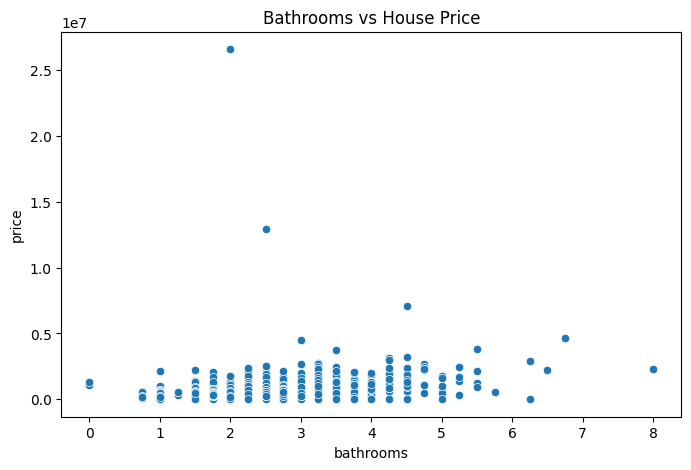

city
Medina                2.046559e+06
Clyde Hill            1.321945e+06
Yarrow Point          1.194838e+06
Mercer Island         1.123818e+06
Bellevue              8.471807e+05
Beaux Arts Village    7.450000e+05
Fall City             6.926818e+05
Sammamish             6.869176e+05
Redmond               6.676495e+05
Newcastle             6.660467e+05
Name: price, dtype: float64
               city  bedrooms  bathrooms  sqft_living       price
4350           Kent       3.0       2.00         1180  26590000.0
4346        Seattle       3.0       2.50         2190  12899000.0
2286       Bellevue       5.0       4.50        10040   7062500.0
2654  Mercer Island       5.0       6.75         9640   4668000.0
2761       Bellevue       4.0       3.00         6430   4489000.0
3729     Clyde Hill       5.0       5.50         7050   3800000.0
1637         Medina       4.0       3.50         5550   3710000.0
252         Seattle       7.0       4.50         6210   3200000.0
1567  Mercer Island    

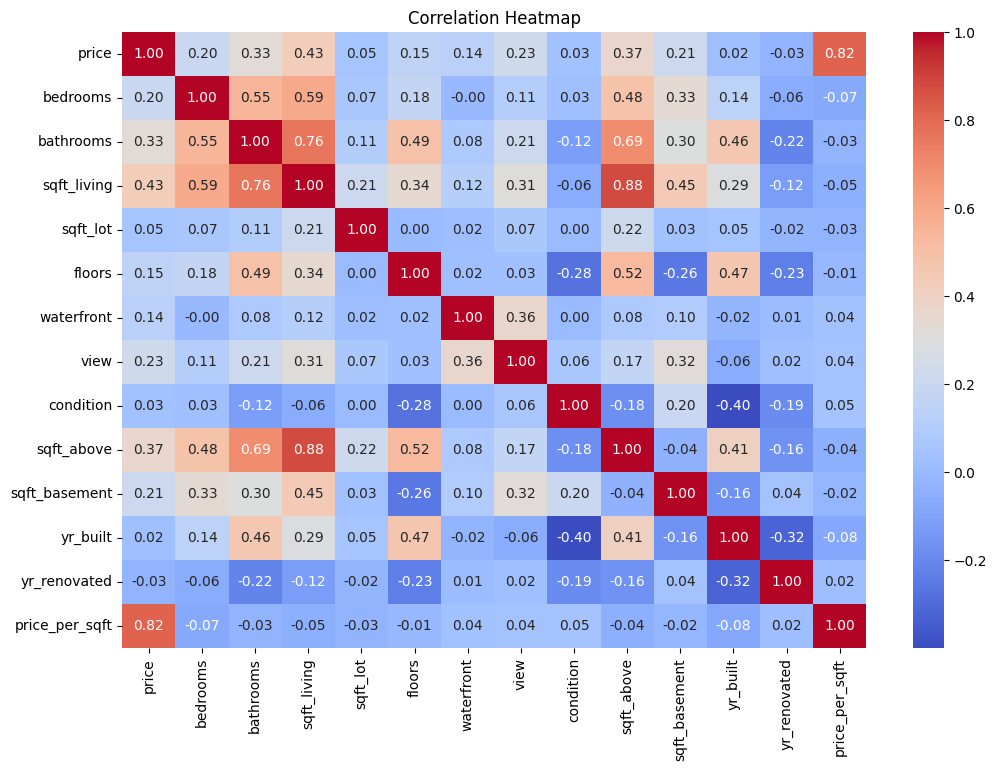

price             1.000000
price_per_sqft    0.819279
sqft_living       0.430410
sqft_above        0.367570
bathrooms         0.327110
view              0.228504
sqft_basement     0.210427
bedrooms          0.200336
floors            0.151461
waterfront        0.135648
sqft_lot          0.050451
condition         0.034915
yr_built          0.021857
yr_renovated     -0.028774
Name: price, dtype: float64
Training Data: (3680, 13)
Testing Data: (920, 13)
Mean Squared Error: 510932371404.30023
Root Mean Squared Error: 714795.3353263438
Mean Absolute Error: 96472.0539243164
R2 Score: 0.4990104378245349


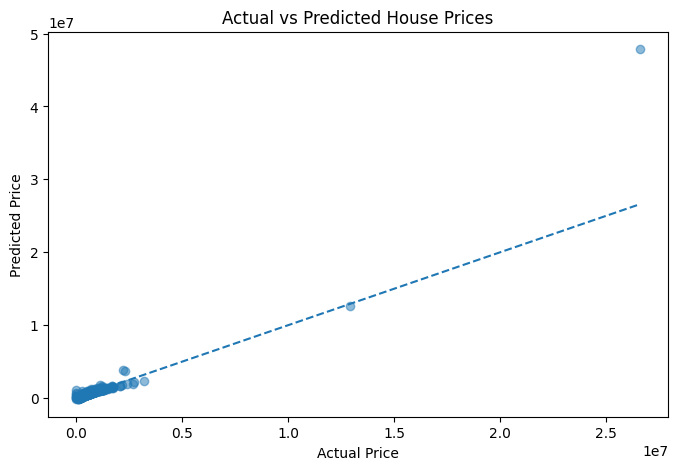

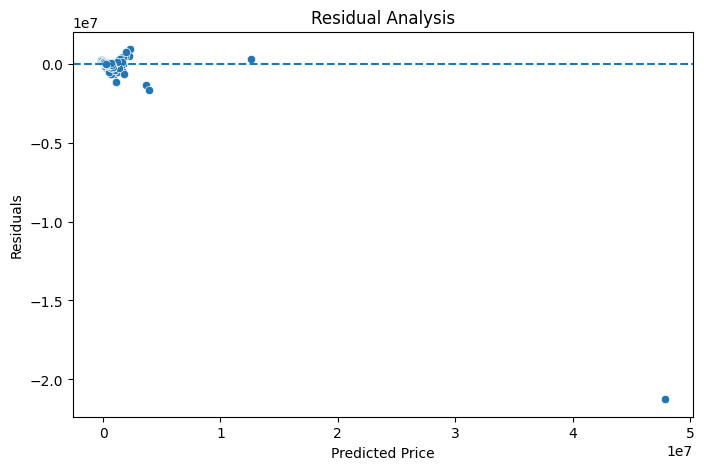

           Feature    Coefficient  Absolute_Coefficient
5       waterfront  218955.674975         218955.674975
4           floors  -12429.915470          12429.915470
6             view    5182.614583           5182.614583
1        bathrooms   -2749.116017           2749.116017
7        condition    2267.668224           2267.668224
12  price_per_sqft    2136.000128           2136.000128
0         bedrooms     457.794679            457.794679
2      sqft_living     197.765428            197.765428
9    sqft_basement     103.756776            103.756776
8       sqft_above      94.008653             94.008653
10        yr_built      57.393221             57.393221
11    yr_renovated       1.021745              1.021745
3         sqft_lot      -0.162826              0.162826
Actual Price: 544000.0
Predicted Price: 579519.6140826195

--- FINAL MODEL SUMMARY ---
Features Used: 13
MSE: 510932371404.30023
RMSE: 714795.3353263438
MAE: 96472.0539243164
R2 Score: 0.4990104378245349


In [1]:
# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Load Dataset
df = pd.read_csv("modified_data.csv")

# 3. Display First 5 Rows
print(df.head())

# 4. Display Last 5 Rows
print(df.tail())

# 5. Dataset Shape
print("Shape:", df.shape)

# 6. Column Names
print(df.columns.tolist())

# 7. Dataset Information
df.info()

# 8. Check Data Types
print(df.dtypes)

# 9. Check Missing Values
print(df.isnull().sum())

# 10. Check Duplicate Rows
print("Duplicates:", df.duplicated().sum())

# 11. Descriptive Statistics
print(df.describe())

# 12. Unique Values in Categorical Columns
print("Cities:", df["city"].nunique())
print("States:", df["statezip"].nunique())
print("Streets:", df["street"].nunique())

# 13. Price Statistics
print("Minimum Price:", df["price"].min())
print("Maximum Price:", df["price"].max())
print("Average Price:", df["price"].mean())
print("Median Price:", df["price"].median())

# 14. Price Distribution
plt.figure(figsize=(8,5))
sns.histplot(df["price"], kde=True)
plt.title("House Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

# 15. Living Area vs Price
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="sqft_living", y="price")
plt.title("Living Area vs House Price")
plt.show()

# 16. Bedrooms vs Price
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="bedrooms", y="price")
plt.title("Bedrooms vs House Price")
plt.show()

# 17. Bathrooms vs Price
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="bathrooms", y="price")
plt.title("Bathrooms vs House Price")
plt.show()

# 18. Price by City
city_price = df.groupby("city")["price"].mean().sort_values(ascending=False)
print(city_price.head(10))

# 19. Top Expensive Houses
print(df.nlargest(10, "price")[["city", "bedrooms", "bathrooms",
                                 "sqft_living", "price"]])

# 20. Correlation Analysis
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12,8))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

# 21. Price Correlation
price_corr = numeric_df.corr()["price"].sort_values(ascending=False)
print(price_corr)

# 22. Select Features
features = [
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "floors",
    "waterfront",
    "view",
    "condition",
    "sqft_above",
    "sqft_basement",
    "yr_built",
    "yr_renovated",
    "price_per_sqft"
]

X = df[features]
y = df["price"]

# 23. Train-Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

# 24. Train Linear Regression
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

# 25. Make Predictions
y_pred = model.predict(X_test)

# 26. Model Evaluation
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("Mean Absolute Error:", mae)
print("R2 Score:", r2)

# 27. Actual vs Predicted
plt.figure(figsize=(8,5))
plt.scatter(y_test, y_pred, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")
plt.show()

# 28. Residual Analysis
residuals = y_test - y_pred

plt.figure(figsize=(8,5))
sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Analysis")
plt.show()

# 29. Coefficient Analysis
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
})

coefficients["Absolute_Coefficient"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

print(coefficients)

# 30. Final Prediction Example
sample = X_test.iloc[[0]]
prediction = model.predict(sample)[0]

print("Actual Price:", y_test.iloc[0])
print("Predicted Price:", prediction)

print("\n--- FINAL MODEL SUMMARY ---")
print("Features Used:", len(features))
print("MSE:", mse)
print("RMSE:", rmse)
print("MAE:", mae)
print("R2 Score:", r2)

Dataset Loaded Successfully!
Shape: (4600, 18)

First 5 Rows:


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft
0,2014-05-02,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,233.58
1,2014-05-02,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,653.15
2,2014-05-02,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,177.20
3,2014-05-02,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,210.00
4,2014-05-02,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,283.51



Last 5 Rows:


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft
4595,2014-07-09,308166.67,3.0,1.75,1510,6360,1.0,0,0,4,1510,0,1954,1979,501 N 143rd St,Seattle,WA 98133,204.08
4596,2014-07-09,534333.33,3.0,2.50,1460,7573,2.0,0,0,3,1460,0,1983,2009,14855 SE 10th Pl,Bellevue,WA 98007,365.98
4597,2014-07-09,416904.17,3.0,2.50,3010,7014,2.0,0,0,3,3010,0,2009,0,759 Ilwaco Pl NE,Renton,WA 98059,138.51
4598,2014-07-10,203400.00,4.0,2.00,2090,6630,1.0,0,0,3,1070,1020,1974,0,5148 S Creston St,Seattle,WA 98178,97.32
4599,2014-07-10,220600.00,3.0,2.50,1490,8102,2.0,0,0,4,1490,0,1990,0,18717 SE 258th St,Covington,WA 98042,148.05



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            4600 non-null   object 
 1   price           4600 non-null   float64
 2   bedrooms        4600 non-null   float64
 3   bathrooms       4600 non-null   float64
 4   sqft_living     4600 non-null   int64  
 5   sqft_lot        4600 non-null   int64  
 6   floors          4600 non-null   float64
 7   waterfront      4600 non-null   int64  
 8   view            4600 non-null   int64  
 9   condition       4600 non-null   int64  
 10  sqft_above      4600 non-null   int64  
 11  sqft_basement   4600 non-null   int64  
 12  yr_built        4600 non-null   int64  
 13  yr_renovated    4600 non-null   int64  
 14  street          4600 non-null   object 
 15  city            4600 non-null   object 
 16  statezip        4600 non-null   object 
 17  price_per_s

...


Top values in city:


city
Seattle        1573
Renton          293
Bellevue        286
Redmond         235
Issaquah        187
Kirkland        187
Kent            185
Auburn          176
Sammamish       175
Federal Way     148
Name: count, dtype: int64


Top values in statezip:


statezip
WA 98103    148
WA 98052    135
WA 98117    132
WA 98115    130
WA 98006    110
WA 98059    106
WA 98042    100
WA 98034     99
WA 98053     98
WA 98074     98
Name: count, dtype: int64

Numerical Columns:
['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'price_per_sqft']

PRICE ANALYSIS
Minimum Price: 0.0
Maximum Price: 26590000.0
Average Price: 551962.9884695652
Median Price: 460943.45999999996
Standard Deviation: 563834.7025446305


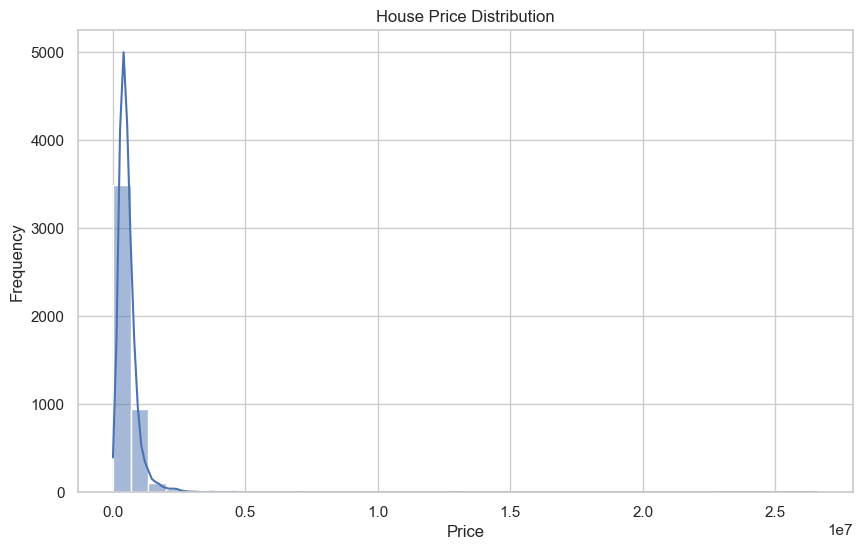

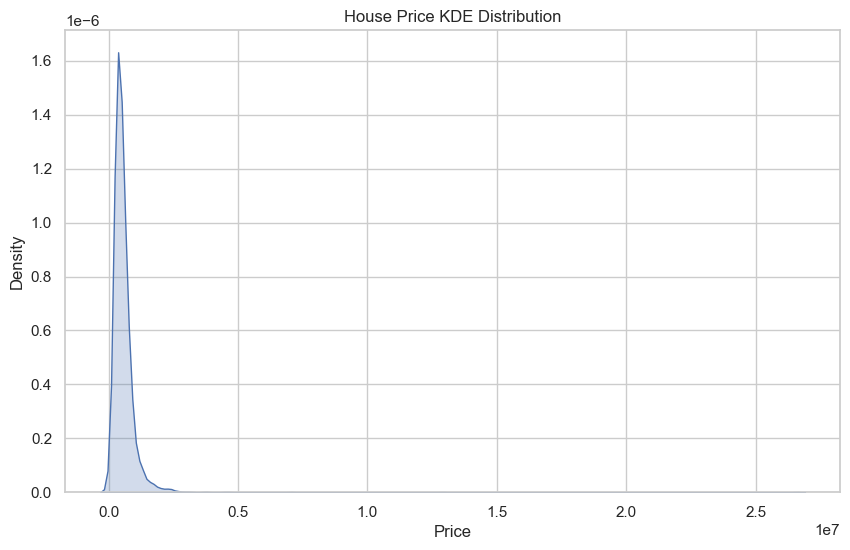

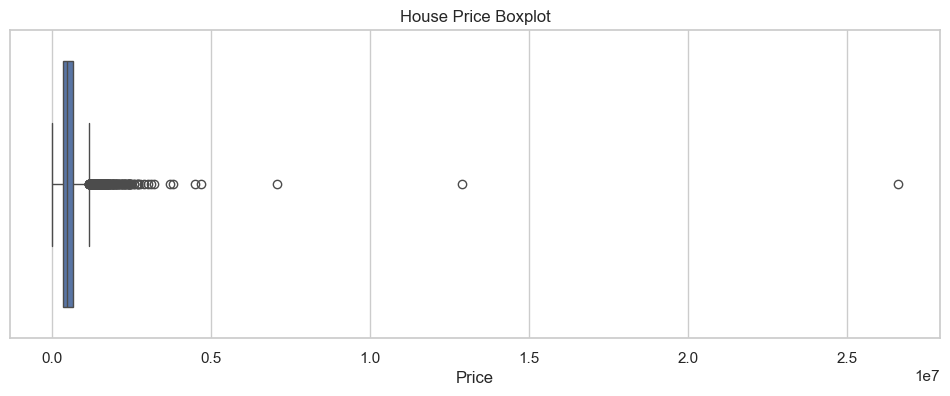

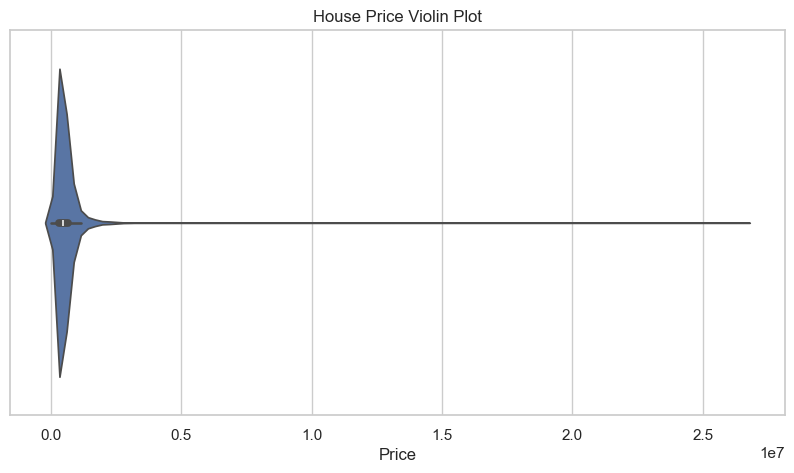

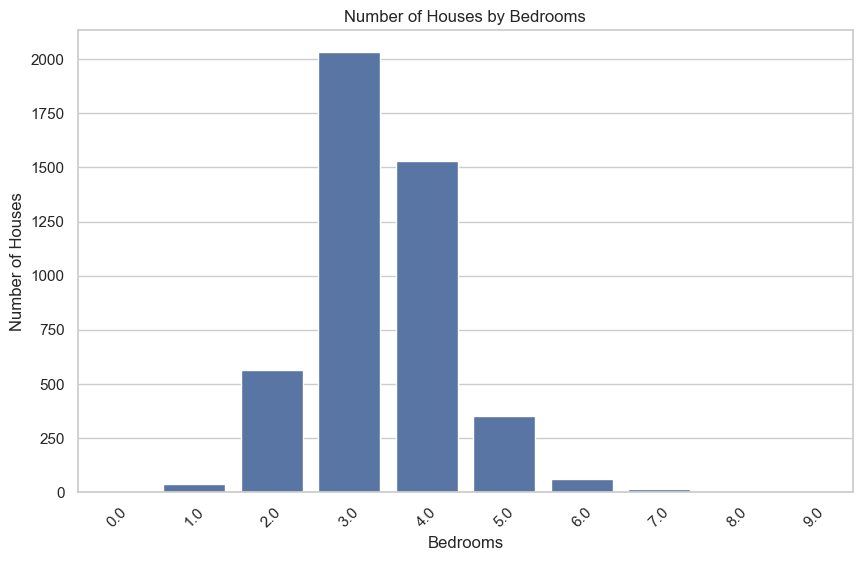

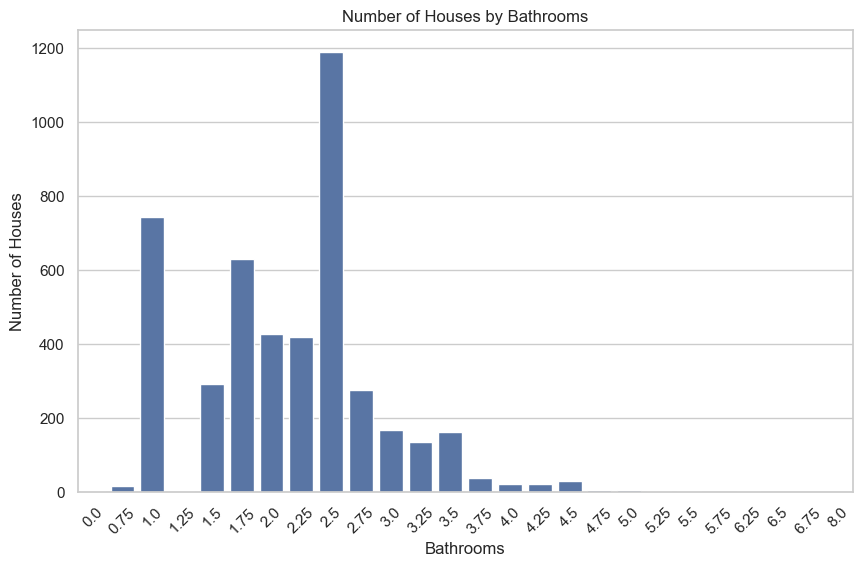

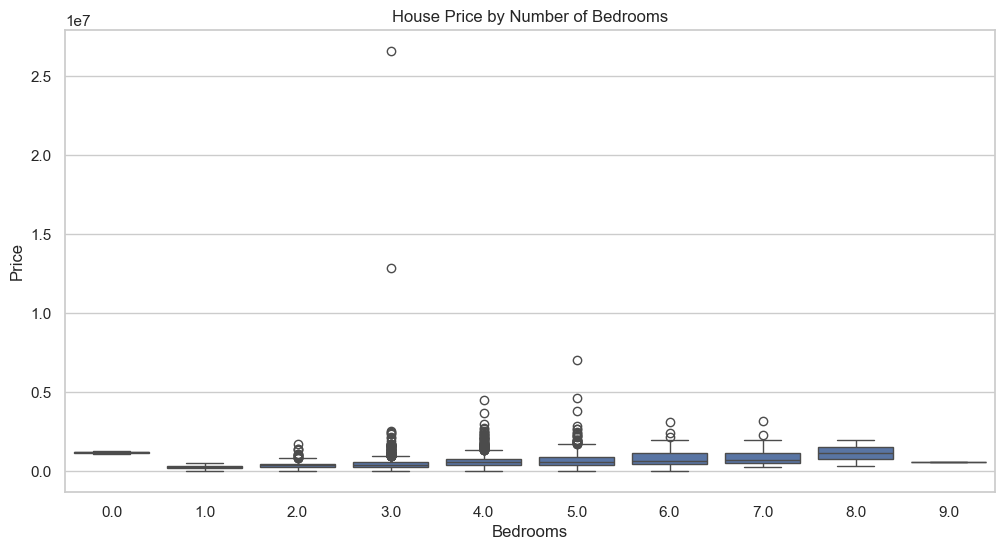

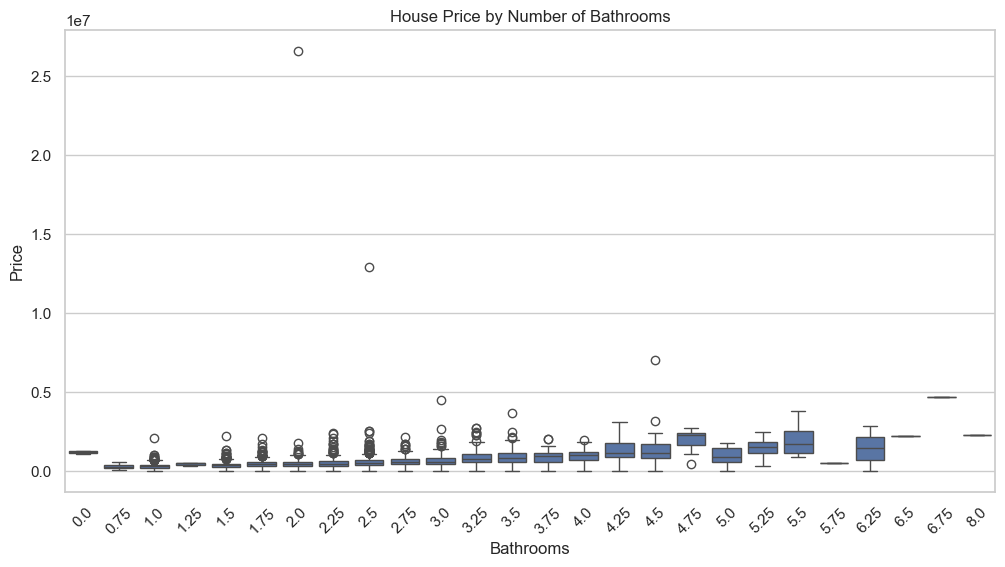

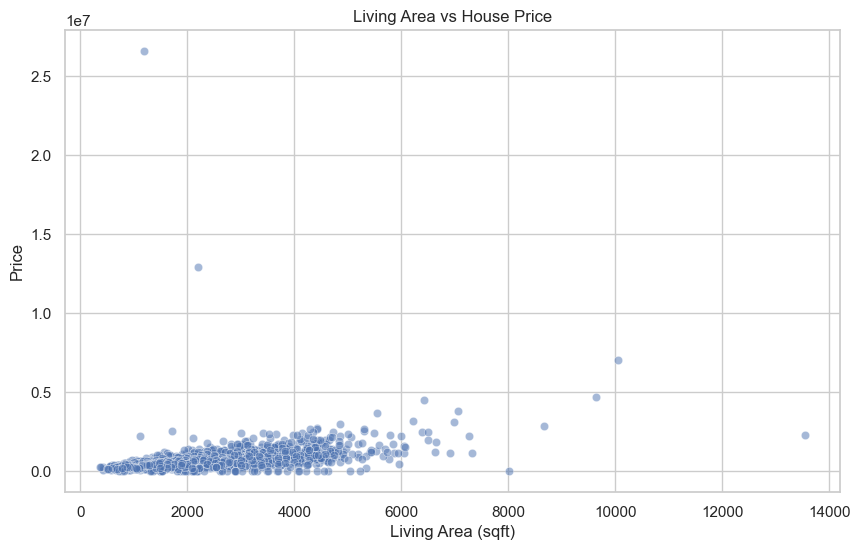

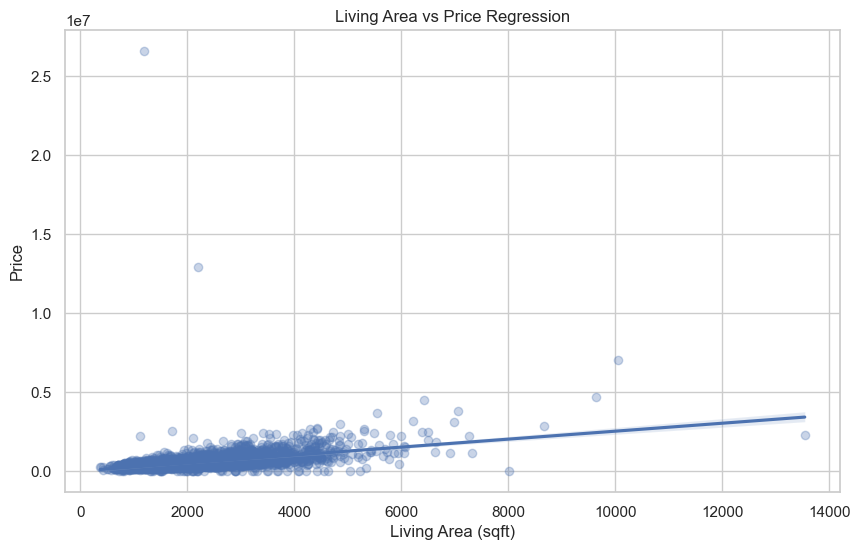

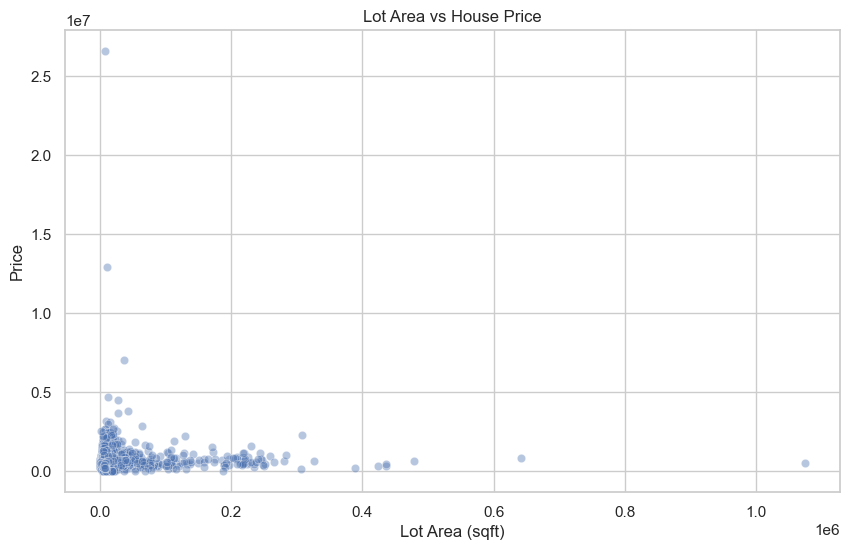

   yr_built  house_age      price
0      1955         71   313000.0
1      1921        105  2384000.0
2      1966         60   342000.0
3      1963         63   420000.0
4      1976         50   550000.0


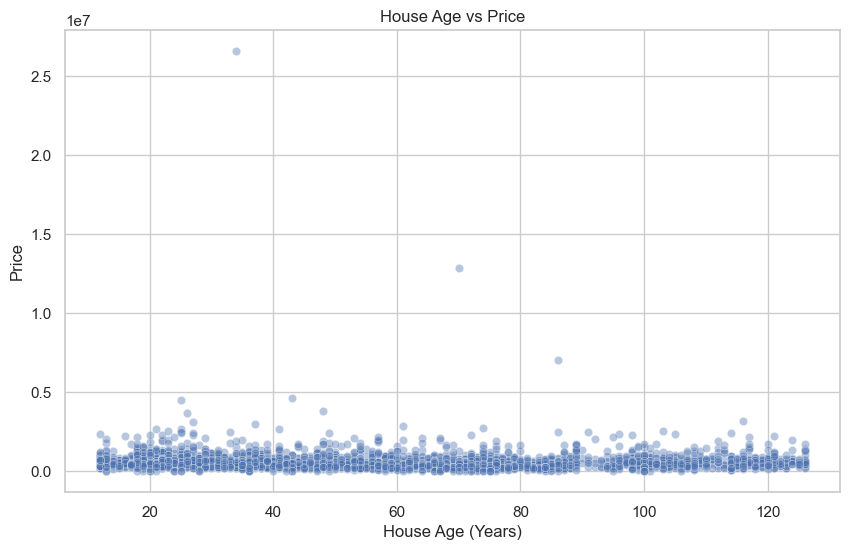

Average Price by Waterfront:


waterfront
0    5.454623e+05
1    1.451621e+06
Name: price, dtype: float64

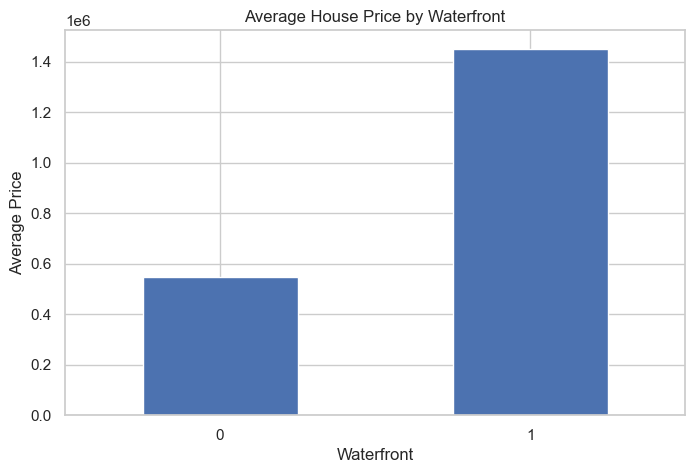

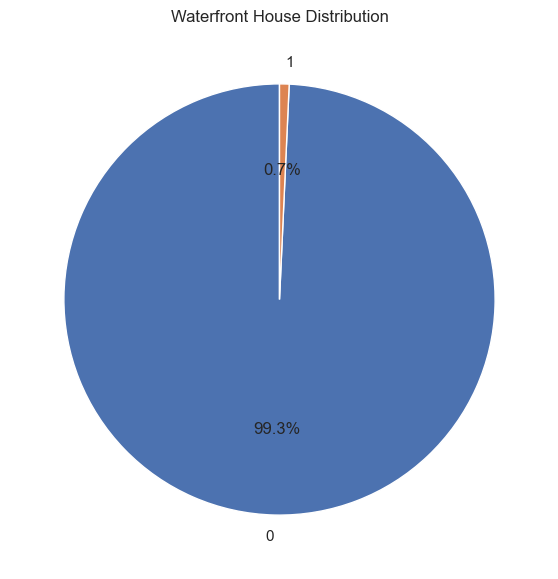

Average Price by Condition:


condition
5    637041.322253
3    550111.516390
4    533647.286070
2    324373.750000
1    306633.333333
Name: price, dtype: float64

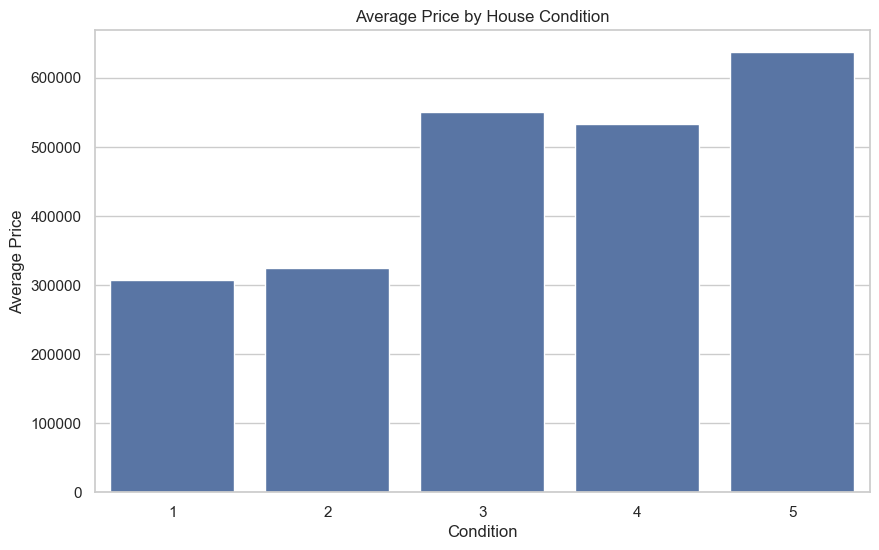

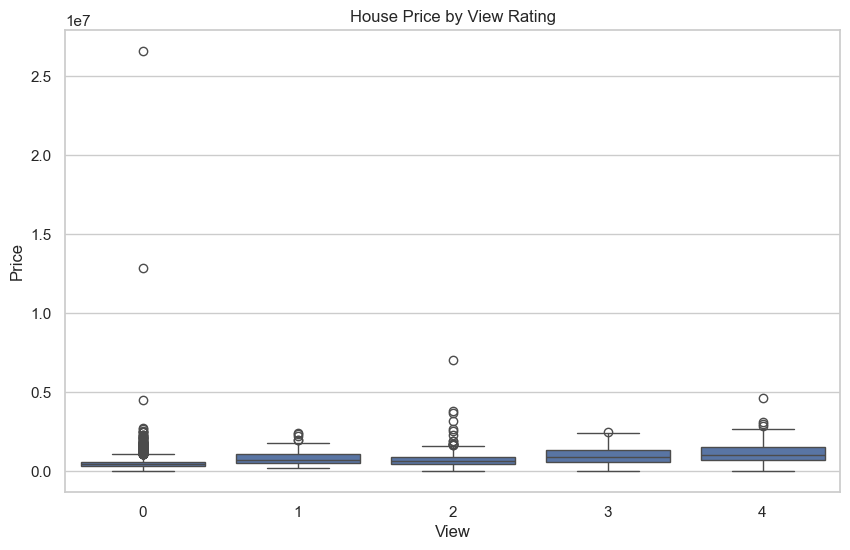

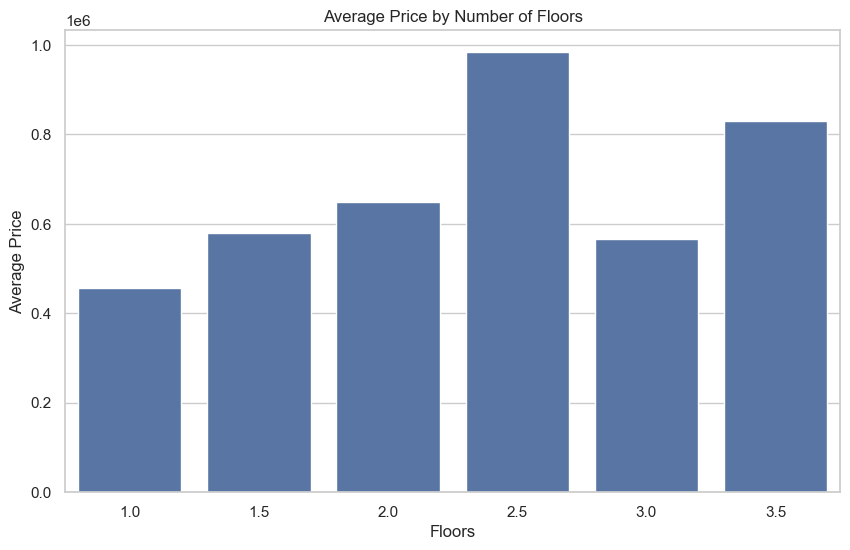

Top 10 Cities by Average Price:


city
Medina                2.046559e+06
Clyde Hill            1.321945e+06
Yarrow Point          1.194838e+06
Mercer Island         1.123818e+06
Bellevue              8.471807e+05
Beaux Arts Village    7.450000e+05
Fall City             6.926818e+05
Sammamish             6.869176e+05
Redmond               6.676495e+05
Newcastle             6.660467e+05
Name: price, dtype: float64

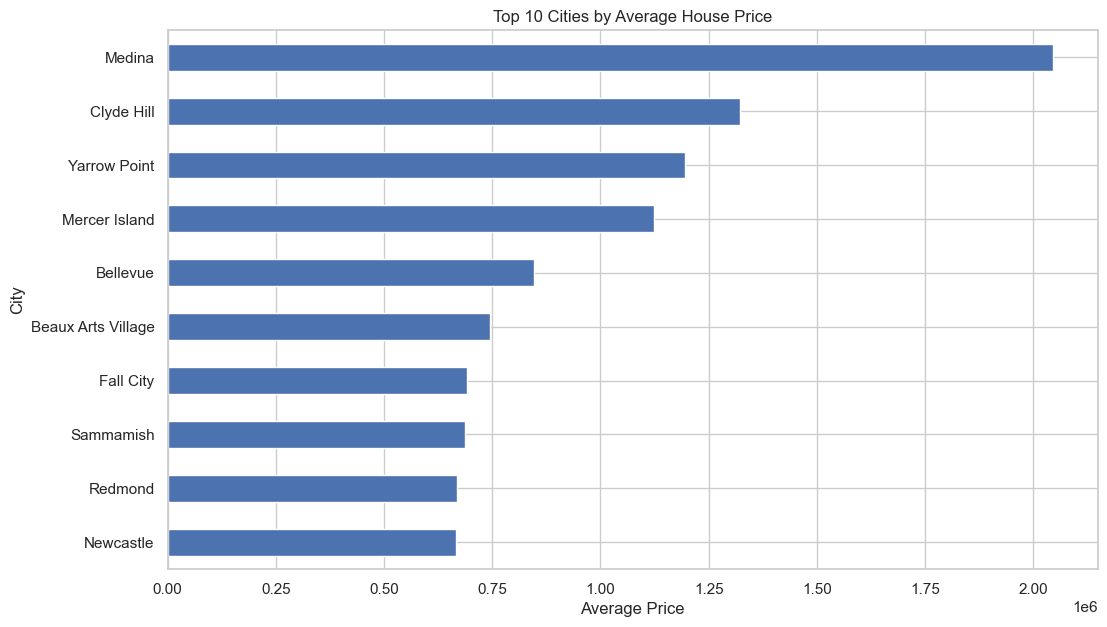

,street,city,statezip,bedrooms,bathrooms,sqft_living,price
4350,12005 SE 219th Ct,Kent,WA 98031,3.0,2.00,1180,26590000.0
4346,5426 40th Ave W,Seattle,WA 98199,3.0,2.50,2190,12899000.0
2286,4442 95th Ave NE,Bellevue,WA 98004,5.0,4.50,10040,7062500.0
2654,5044 Butterworth Rd,Mercer Island,WA 98040,5.0,6.75,9640,4668000.0
2761,1149-1199 91st Ave NE,Bellevue,WA 98004,4.0,3.00,6430,4489000.0
3729,1365 91st Ave NE,Clyde Hill,WA 98004,5.0,5.50,7050,3800000.0
1637,3222 78th Pl NE,Medina,WA 98039,4.0,3.50,5550,3710000.0
252,1230 Warren Ave N,Seattle,WA 98109,7.0,4.50,6210,3200000.0
1567,5243 Forest Ave SE,Mercer Island,WA 98040,6.0,4.25,6980,3100000.0
2772,11031 Champagne Point Rd NE,Kirkland,WA 98034,4.0,4.25,4850,3000000.0


,street,city,sqft_living,bedrooms,bathrooms,price
122,26408 NE 70th St,Redmond,13540,7.0,8.00,2280000.0
2286,4442 95th Ave NE,Bellevue,10040,5.0,4.50,7062500.0
2654,5044 Butterworth Rd,Mercer Island,9640,5.0,6.75,4668000.0
2328,1291 NW Elford Dr,Seattle,8670,5.0,6.25,2888000.0
4575,2 Crescent Key,Bellevue,8020,5.0,6.25,0.0
4138,19100 SE 174th St,Renton,7320,5.0,4.00,1135250.0
462,7070 270th Pl SE,Issaquah,7270,5.0,6.50,2238888.0
3729,1365 91st Ave NE,Clyde Hill,7050,5.0,5.50,3800000.0
1567,5243 Forest Ave SE,Mercer Island,6980,6.0,4.25,3100000.0
2967,16903 246th Ave NE,Woodinville,6900,6.0,4.25,1135000.0


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,price_per_sqft,house_age
price,1.000000,0.200336,0.327110,0.430410,0.050451,0.151461,0.135648,0.228504,0.034915,0.367570,0.210427,0.021857,-0.028774,0.819279,-0.021857
bedrooms,0.200336,1.000000,0.545920,0.594884,0.068819,0.177895,-0.003483,0.111028,0.025080,0.484705,0.334165,0.142461,-0.061082,-0.072955,-0.142461
bathrooms,0.327110,0.545920,1.000000,0.761154,0.107837,0.486428,0.076232,0.211960,-0.119994,0.689918,0.298020,0.463498,-0.215886,-0.033265,-0.463498
sqft_living,0.430410,0.594884,0.761154,1.000000,0.210538,0.344850,0.117616,0.311009,-0.062826,0.876443,0.447206,0.287775,-0.122817,-0.048910,-0.287775
sqft_lot,0.050451,0.068819,0.107837,0.210538,1.000000,0.003750,0.017241,0.073907,0.000558,0.216455,0.034842,0.050706,-0.022730,-0.028022,-0.050706
floors,0.151461,0.177895,0.486428,0.344850,0.003750,1.000000,0.022024,0.031211,-0.275013,0.522814,-0.255510,0.467481,-0.233996,-0.009996,-0.467481
waterfront,0.135648,-0.003483,0.076232,0.117616,0.017241,0.022024,1.000000,0.360935,0.000352,0.078911,0.097501,-0.023563,0.008625,0.035487,0.023563
view,0.228504,0.111028,0.211960,0.311009,0.073907,0.031211,0.360935,1.000000,0.063077,0.174327,0.321602,-0.064465,0.022967,0.042666,0.064465
condition,0.034915,0.025080,-0.119994,-0.062826,0.000558,-0.275013,0.000352,0.063077,1.000000,-0.178196,0.200632,-0.399698,-0.186818,0.046842,0.399698
sqft_above,0.367570,0.484705,0.689918,0.876443,0.216455,0.522814,0.078911,0.174327,-0.178196,1.000000,-0.038723,0.408535,-0.160426,-0.044942,-0.408535


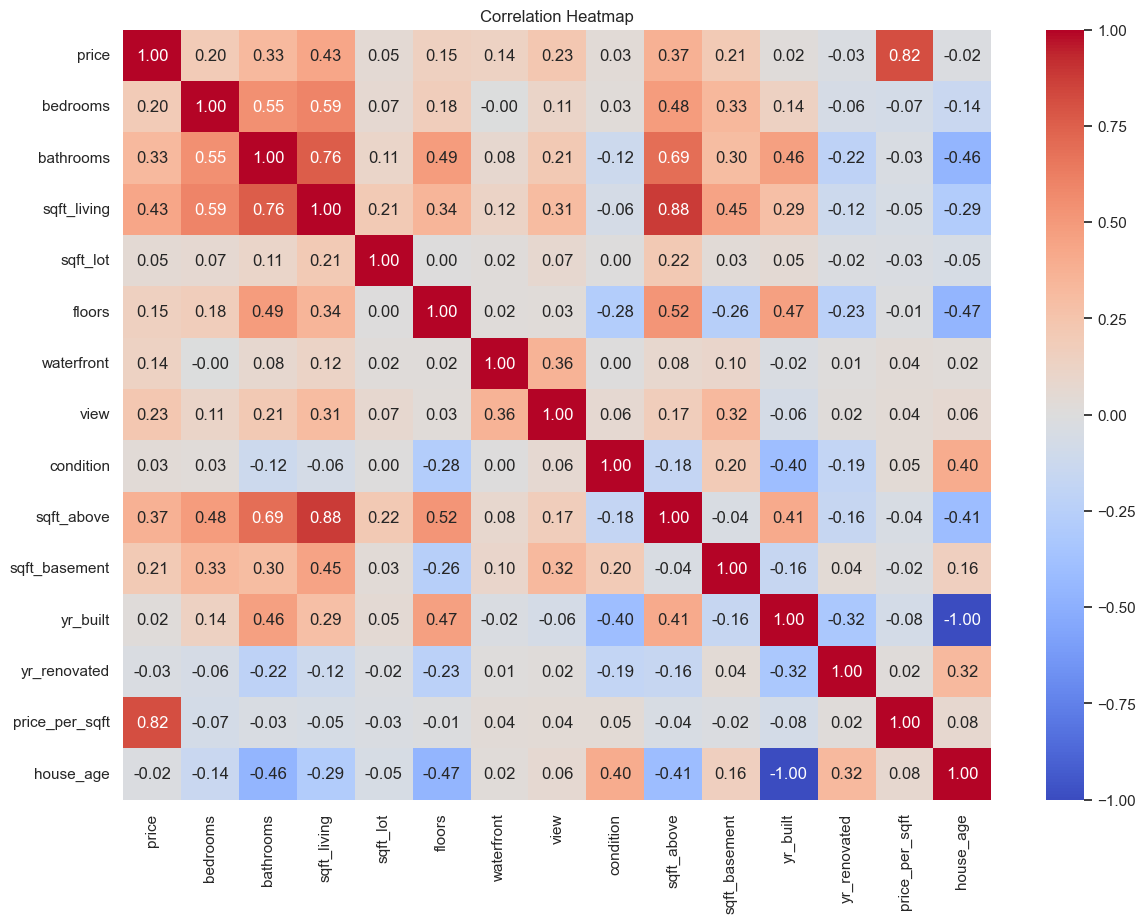

Features Correlated with Price:


price             1.000000
price_per_sqft    0.819279
sqft_living       0.430410
sqft_above        0.367570
bathrooms         0.327110
view              0.228504
sqft_basement     0.210427
bedrooms          0.200336
floors            0.151461
waterfront        0.135648
sqft_lot          0.050451
condition         0.034915
yr_built          0.021857
house_age        -0.021857
yr_renovated     -0.028774
Name: price, dtype: float64

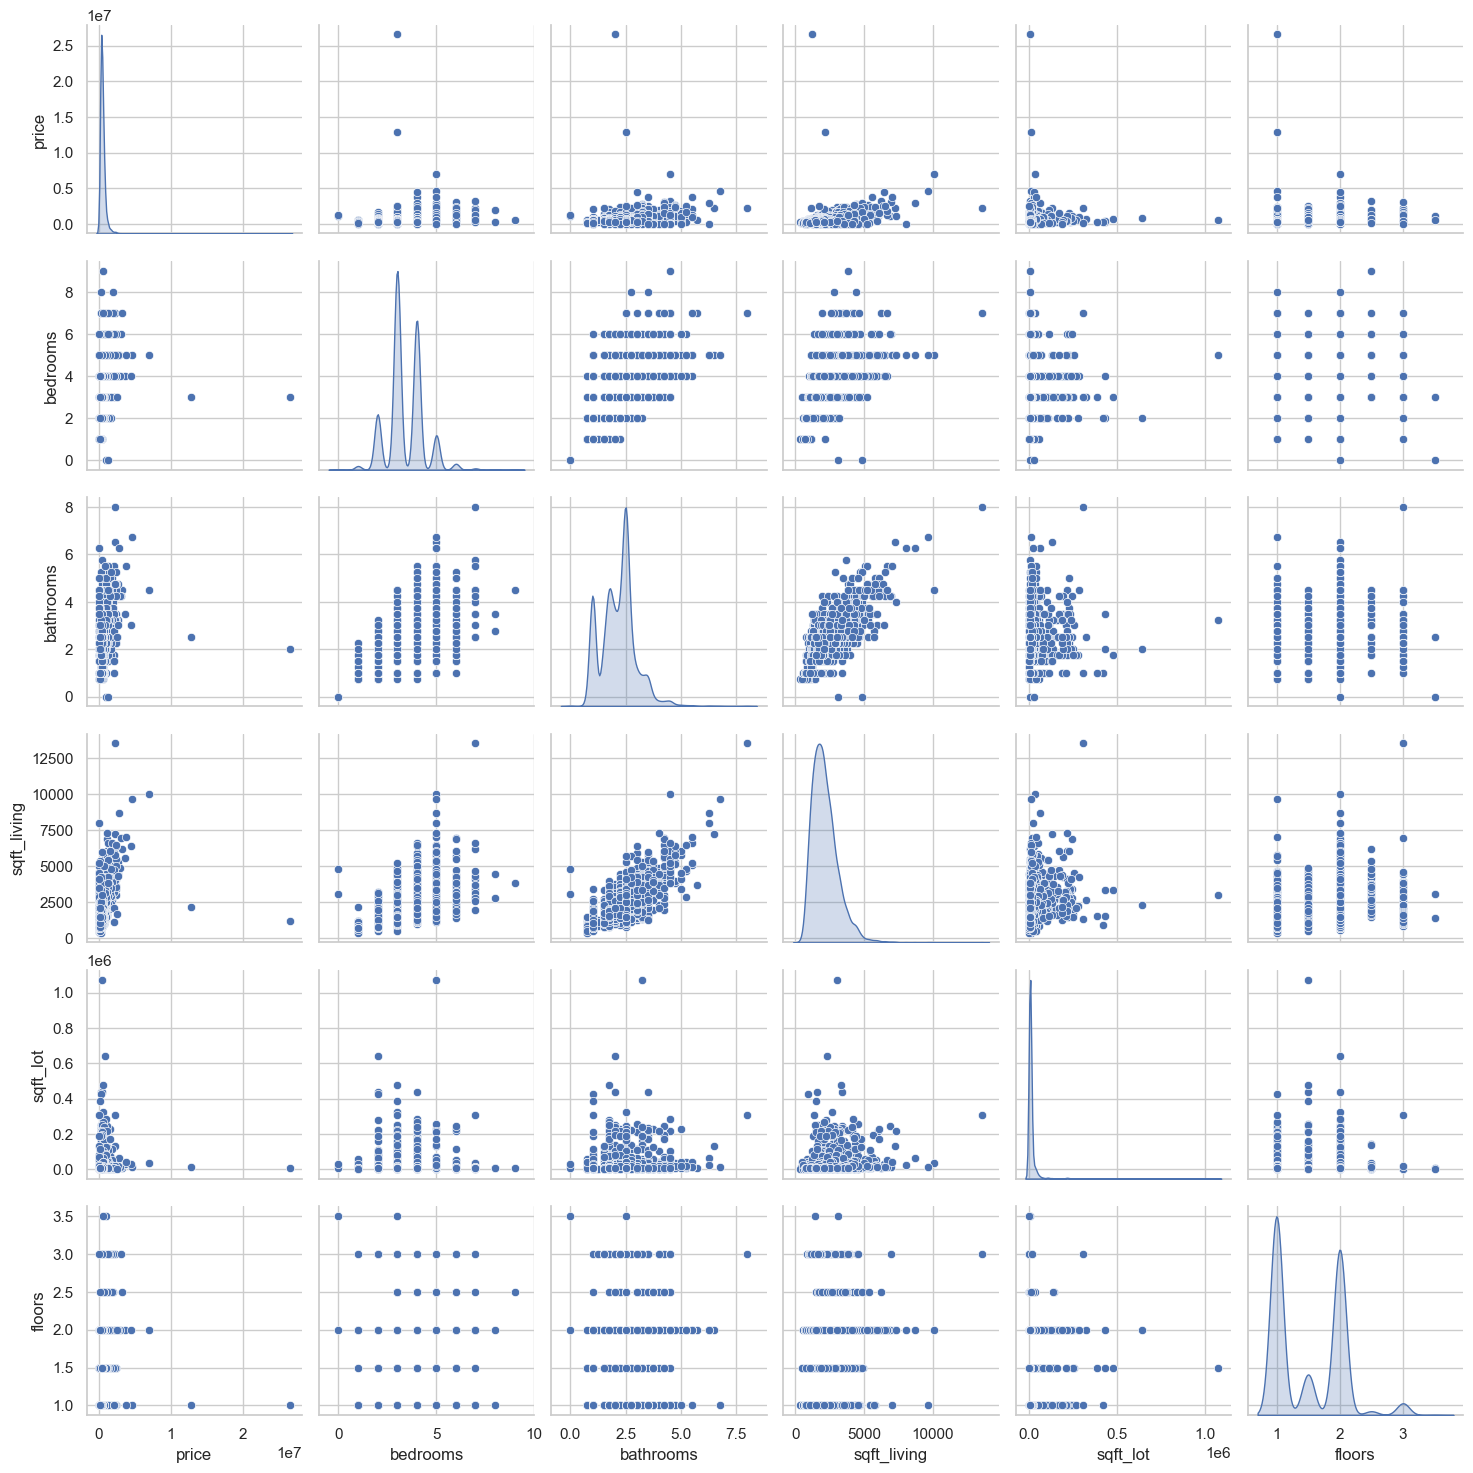

Number of Price Outliers: 240
Lower Bound: -175256.25
Upper Bound: 1153093.75


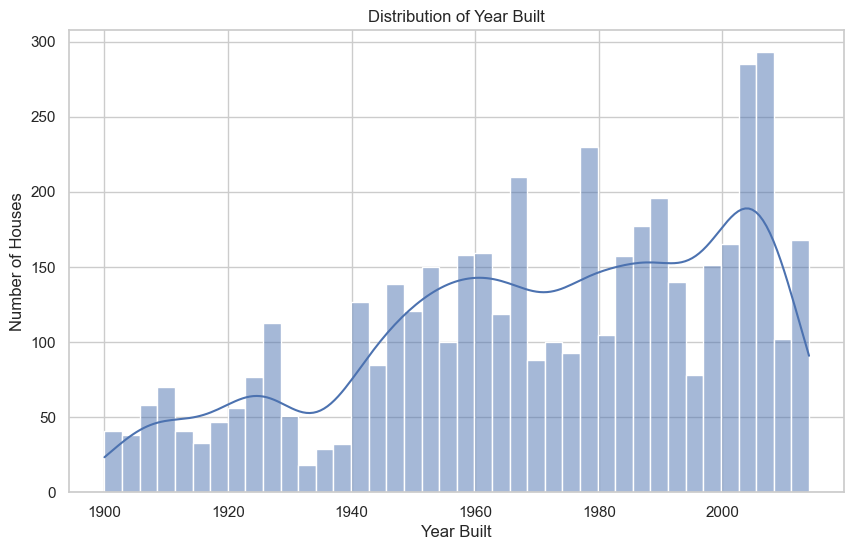

Not Renovated    2735
Renovated        1865
Name: count, dtype: int64


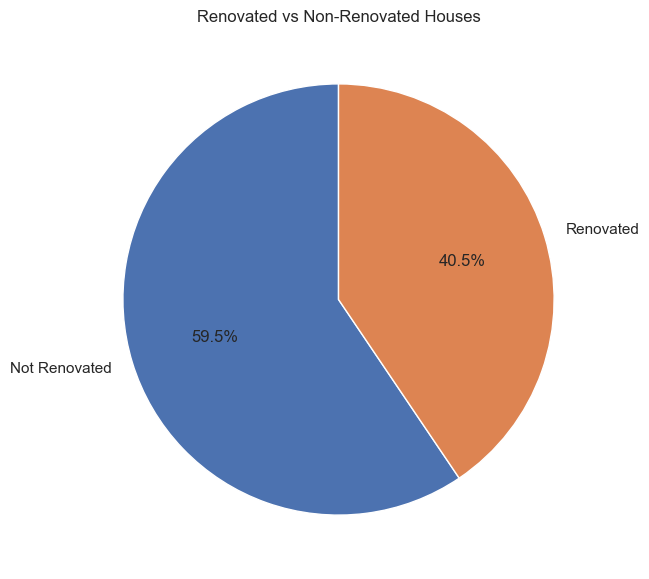

renovation_status
Not Renovated    565275.243678
Renovated        532440.726810
Name: price, dtype: float64

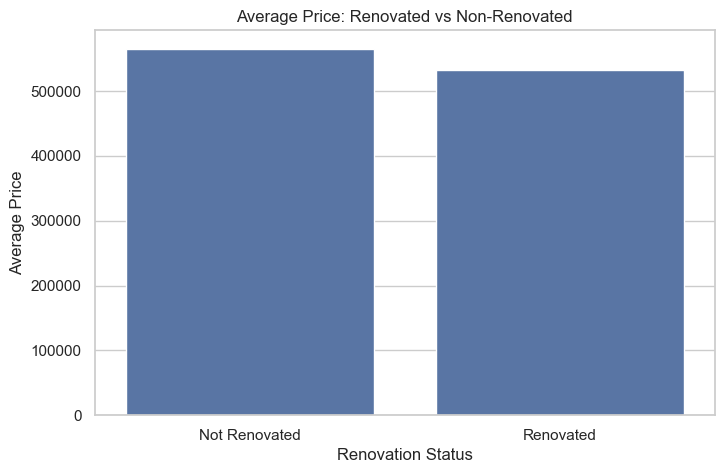

        date  year  month
0 2014-05-02  2014      5
1 2014-05-02  2014      5
2 2014-05-02  2014      5
3 2014-05-02  2014      5
4 2014-05-02  2014      5


,year,price
0,2014,551962.98847


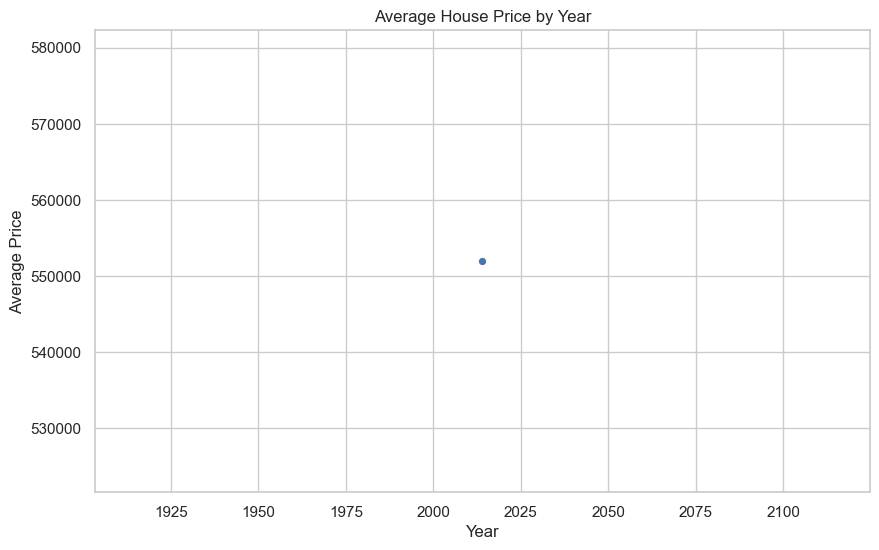

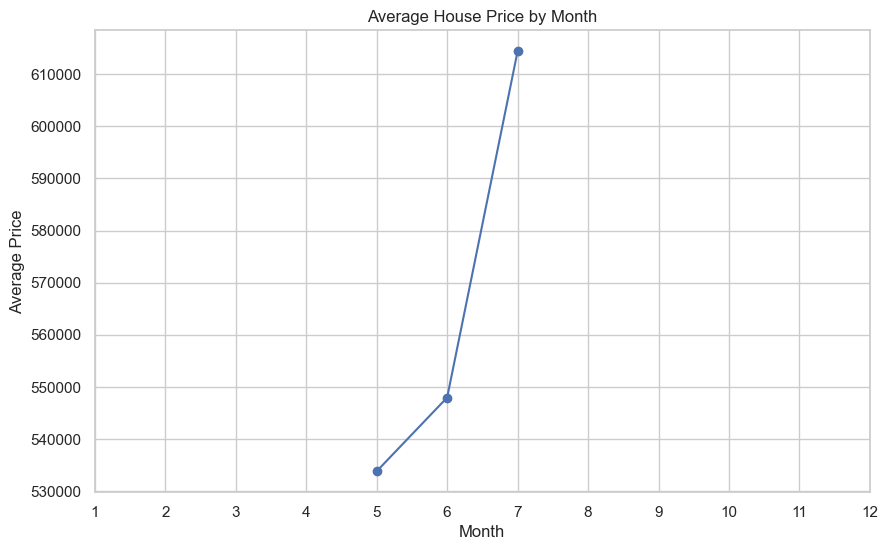

   sqft_living  sqft_basement  total_sqft  house_age
0         1340              0        1340         71
1         3650            280        3930        105
2         1930              0        1930         60
3         2000           1000        3000         63
4         1940            800        2740         50
Features:
['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'house_age', 'total_sqft', 'city', 'statezip']
Numerical Features:
['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'house_age', 'total_sqft']

Categorical Features:
['city', 'statezip']
X_train: (3680, 16)
X_test: (920, 16)
y_train: (3680,)
y_test: (920,)
Linear Regression Model Trained Successfully!
Predictions Generated Successfully!

MODEL PERFORMANCE
----------------------------------------
MSE : 96

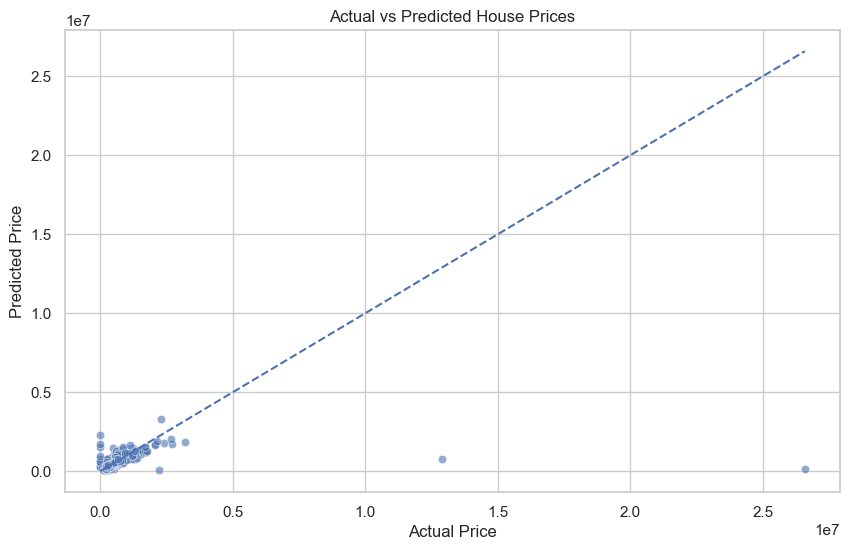

Residual Statistics:


count    9.200000e+02
mean     3.403547e+04
std      9.816532e+05
min     -2.263357e+06
25%     -6.684878e+04
50%      6.286909e+03
75%      7.389768e+04
max      2.642437e+07
Name: price, dtype: float64

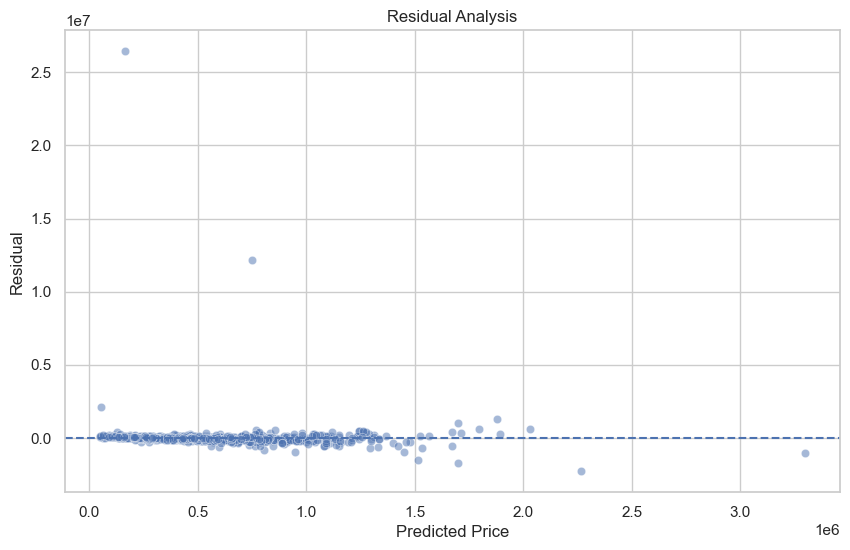

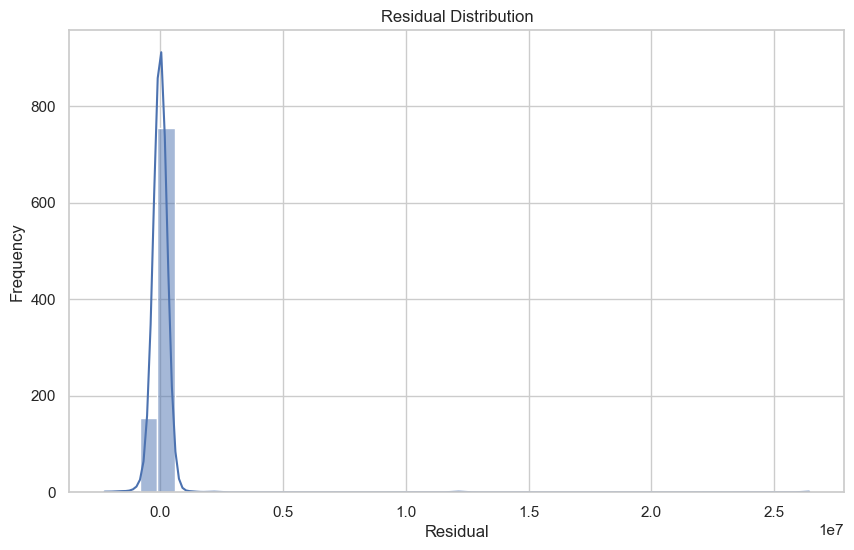

In [ ]:
# ============================================================
# HOUSE PRICE PREDICTION - COMPLETE PRODUCTION ANALYSIS
# ============================================================

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Plot settings
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)


# ============================================================
# 2. LOAD DATASET
# ============================================================

df = pd.read_csv("modified_data.csv")

print("Dataset Loaded Successfully!")
print("Shape:", df.shape)


# ============================================================
# 3. FIRST 5 RECORDS
# ============================================================

print("\nFirst 5 Rows:")
display(df.head())


# ============================================================
# 4. LAST 5 RECORDS
# ============================================================

print("\nLast 5 Rows:")
display(df.tail())


# ============================================================
# 5. DATASET INFORMATION
# ============================================================

print("\nDataset Information:")
df.info()


# ============================================================
# 6. COLUMN NAMES
# ============================================================

print("\nColumns:")
print(df.columns.tolist())


# ============================================================
# 7. DATA TYPES
# ============================================================

print("\nData Types:")
display(df.dtypes.to_frame("Data Type"))


# ============================================================
# 8. DATASET SHAPE
# ============================================================

rows, columns = df.shape

print("Number of Rows:", rows)
print("Number of Columns:", columns)


# ============================================================
# 9. MISSING VALUES
# ============================================================

missing = df.isnull().sum()

missing_df = pd.DataFrame({
    "Column": missing.index,
    "Missing Values": missing.values,
    "Missing %": (missing.values / len(df)) * 100
})

display(missing_df)


# ============================================================
# 10. DUPLICATE RECORDS
# ============================================================

duplicates = df.duplicated().sum()

print("Duplicate Rows:", duplicates)

if duplicates > 0:
    df = df.drop_duplicates().reset_index(drop=True)

print("Shape After Removing Duplicates:", df.shape)


# ============================================================
# 11. DESCRIPTIVE STATISTICS
# ============================================================

print("\nDescriptive Statistics:")
display(df.describe().T)


# ============================================================
# 12. UNIQUE VALUES
# ============================================================

print("\nUnique Values Per Column:")

unique_df = pd.DataFrame({
    "Column": df.columns,
    "Unique Values": [df[col].nunique() for col in df.columns]
})

display(unique_df)


# ============================================================
# 13. CATEGORICAL COLUMN ANALYSIS
# ============================================================

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical Columns:")
print(categorical_columns)

for col in categorical_columns:
    print(f"\nTop values in {col}:")
    display(df[col].value_counts().head(10))


# ============================================================
# 14. NUMERICAL COLUMN ANALYSIS
# ============================================================

numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)


# ============================================================
# 15. PRICE SUMMARY
# ============================================================

print("\nPRICE ANALYSIS")

print("Minimum Price:", df["price"].min())
print("Maximum Price:", df["price"].max())
print("Average Price:", df["price"].mean())
print("Median Price:", df["price"].median())
print("Standard Deviation:", df["price"].std())


# ============================================================
# 16. HISTOGRAM - PRICE DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

sns.histplot(
    df["price"],
    bins=40,
    kde=True
)

plt.title("House Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()


# ============================================================
# 17. KDE PLOT - PRICE
# ============================================================

plt.figure(figsize=(10, 6))

sns.kdeplot(
    data=df,
    x="price",
    fill=True
)

plt.title("House Price KDE Distribution")
plt.xlabel("Price")
plt.ylabel("Density")
plt.show()


# ============================================================
# 18. BOXPLOT - PRICE OUTLIERS
# ============================================================

plt.figure(figsize=(12, 4))

sns.boxplot(
    x=df["price"]
)

plt.title("House Price Boxplot")
plt.xlabel("Price")
plt.show()


# ============================================================
# 19. VIOLIN PLOT - PRICE
# ============================================================

plt.figure(figsize=(10, 5))

sns.violinplot(
    x=df["price"]
)

plt.title("House Price Violin Plot")
plt.xlabel("Price")
plt.show()


# ============================================================
# 20. BEDROOM DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="bedrooms"
)

plt.title("Number of Houses by Bedrooms")
plt.xlabel("Bedrooms")
plt.ylabel("Number of Houses")
plt.xticks(rotation=45)
plt.show()


# ============================================================
# 21. BATHROOM DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="bathrooms"
)

plt.title("Number of Houses by Bathrooms")
plt.xlabel("Bathrooms")
plt.ylabel("Number of Houses")
plt.xticks(rotation=45)
plt.show()


# ============================================================
# 22. HOUSE PRICE BY BEDROOMS - BOXPLOT
# ============================================================

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="bedrooms",
    y="price"
)

plt.title("House Price by Number of Bedrooms")
plt.xlabel("Bedrooms")
plt.ylabel("Price")
plt.show()


# ============================================================
# 23. HOUSE PRICE BY BATHROOMS
# ============================================================

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="bathrooms",
    y="price"
)

plt.title("House Price by Number of Bathrooms")
plt.xlabel("Bathrooms")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.show()


# ============================================================
# 24. SQFT LIVING VS PRICE - SCATTER PLOT
# ============================================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="sqft_living",
    y="price",
    alpha=0.5
)

plt.title("Living Area vs House Price")
plt.xlabel("Living Area (sqft)")
plt.ylabel("Price")
plt.show()


# ============================================================
# 25. SQFT LIVING VS PRICE - REGRESSION PLOT
# ============================================================

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="sqft_living",
    y="price",
    scatter_kws={"alpha": 0.3},
    line_kws={}
)

plt.title("Living Area vs Price Regression")
plt.xlabel("Living Area (sqft)")
plt.ylabel("Price")
plt.show()


# ============================================================
# 26. SQFT LOT VS PRICE
# ============================================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="sqft_lot",
    y="price",
    alpha=0.4
)

plt.title("Lot Area vs House Price")
plt.xlabel("Lot Area (sqft)")
plt.ylabel("Price")
plt.show()


# ============================================================
# 27. HOUSE AGE ANALYSIS
# ============================================================

current_year = 2026

df["house_age"] = current_year - df["yr_built"]

print(df[["yr_built", "house_age", "price"]].head())


# ============================================================
# 28. HOUSE AGE VS PRICE
# ============================================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="house_age",
    y="price",
    alpha=0.4
)

plt.title("House Age vs Price")
plt.xlabel("House Age (Years)")
plt.ylabel("Price")
plt.show()


# ============================================================
# 29. WATERFRONT ANALYSIS
# ============================================================

waterfront_price = df.groupby(
    "waterfront"
)["price"].mean()

print("Average Price by Waterfront:")
display(waterfront_price)


# ============================================================
# 30. WATERFRONT PRICE - BAR CHART
# ============================================================

plt.figure(figsize=(8, 5))

waterfront_price.plot(
    kind="bar"
)

plt.title("Average House Price by Waterfront")
plt.xlabel("Waterfront")
plt.ylabel("Average Price")
plt.xticks(rotation=0)
plt.show()


# ============================================================
# 31. WATERFRONT PRICE - PIE CHART
# ============================================================

waterfront_count = df["waterfront"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    waterfront_count.values,
    labels=waterfront_count.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Waterfront House Distribution")
plt.show()


# ============================================================
# 32. CONDITION VS PRICE
# ============================================================

condition_price = df.groupby(
    "condition"
)["price"].mean().sort_values(ascending=False)

print("Average Price by Condition:")
display(condition_price)


plt.figure(figsize=(10, 6))

sns.barplot(
    x=condition_price.index,
    y=condition_price.values
)

plt.title("Average Price by House Condition")
plt.xlabel("Condition")
plt.ylabel("Average Price")
plt.show()


# ============================================================
# 33. VIEW VS PRICE
# ============================================================

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="view",
    y="price"
)

plt.title("House Price by View Rating")
plt.xlabel("View")
plt.ylabel("Price")
plt.show()


# ============================================================
# 34. FLOORS VS PRICE
# ============================================================

floor_price = df.groupby(
    "floors"
)["price"].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=floor_price.index,
    y=floor_price.values
)

plt.title("Average Price by Number of Floors")
plt.xlabel("Floors")
plt.ylabel("Average Price")
plt.show()


# ============================================================
# 35. TOP 10 CITIES BY AVERAGE PRICE
# ============================================================

city_price = (
    df.groupby("city")["price"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Cities by Average Price:")
display(city_price)


plt.figure(figsize=(12, 7))

city_price.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Cities by Average House Price")
plt.xlabel("Average Price")
plt.ylabel("City")
plt.show()


# ============================================================
# 36. TOP 10 MOST EXPENSIVE HOUSES
# ============================================================

top_houses = df.nlargest(
    10,
    "price"
)[
    [
        "street",
        "city",
        "statezip",
        "bedrooms",
        "bathrooms",
        "sqft_living",
        "price"
    ]
]

display(top_houses)


# ============================================================
# 37. TOP 10 LARGEST HOUSES
# ============================================================

largest_houses = df.nlargest(
    10,
    "sqft_living"
)[
    [
        "street",
        "city",
        "sqft_living",
        "bedrooms",
        "bathrooms",
        "price"
    ]
]

display(largest_houses)


# ============================================================
# 38. CORRELATION MATRIX
# ============================================================

correlation = df.select_dtypes(
    include=np.number
).corr()

display(correlation)


# ============================================================
# 39. CORRELATION HEATMAP
# ============================================================

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.show()


# ============================================================
# 40. PRICE CORRELATION
# ============================================================

price_correlation = (
    correlation["price"]
    .sort_values(ascending=False)
)

print("Features Correlated with Price:")
display(price_correlation)


# ============================================================
# 41. PAIRPLOT
# ============================================================

pair_columns = [
    "price",
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "floors"
]

sns.pairplot(
    df[pair_columns].dropna(),
    diag_kind="kde"
)

plt.show()


# ============================================================
# 42. OUTLIER ANALYSIS - IQR
# ============================================================

Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["price"] < lower_bound) |
    (df["price"] > upper_bound)
]

print("Number of Price Outliers:", len(outliers))
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)


# ============================================================
# 43. YEAR BUILT DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="yr_built",
    bins=40,
    kde=True
)

plt.title("Distribution of Year Built")
plt.xlabel("Year Built")
plt.ylabel("Number of Houses")
plt.show()


# ============================================================
# 44. RENOVATED VS NON-RENOVATED
# ============================================================

renovated = np.where(
    df["yr_renovated"] > 0,
    "Renovated",
    "Not Renovated"
)

renovated_count = pd.Series(renovated).value_counts()

print(renovated_count)


plt.figure(figsize=(7, 7))

plt.pie(
    renovated_count.values,
    labels=renovated_count.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Renovated vs Non-Renovated Houses")
plt.show()


# ============================================================
# 45. RENOVATION STATUS VS PRICE
# ============================================================

df["renovation_status"] = np.where(
    df["yr_renovated"] > 0,
    "Renovated",
    "Not Renovated"
)

renovation_price = df.groupby(
    "renovation_status"
)["price"].mean()

display(renovation_price)


plt.figure(figsize=(8, 5))

sns.barplot(
    x=renovation_price.index,
    y=renovation_price.values
)

plt.title("Average Price: Renovated vs Non-Renovated")
plt.xlabel("Renovation Status")
plt.ylabel("Average Price")
plt.show()


# ============================================================
# 46. DATE ANALYSIS
# ============================================================

df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

print(df[["date", "year", "month"]].head())


# ============================================================
# 47. YEARLY PRICE TREND
# ============================================================

yearly_price = (
    df.groupby("year")["price"]
    .mean()
    .reset_index()
)

display(yearly_price)


plt.figure(figsize=(10, 6))

sns.lineplot(
    data=yearly_price,
    x="year",
    y="price",
    marker="o"
)

plt.title("Average House Price by Year")
plt.xlabel("Year")
plt.ylabel("Average Price")
plt.show()


# ============================================================
# 48. MONTHLY PRICE TREND
# ============================================================

monthly_price = (
    df.groupby("month")["price"]
    .mean()
)

plt.figure(figsize=(10, 6))

monthly_price.plot(
    kind="line",
    marker="o"
)

plt.title("Average House Price by Month")
plt.xlabel("Month")
plt.ylabel("Average Price")
plt.xticks(range(1, 13))
plt.show()


# ============================================================
# 49. FEATURE ENGINEERING
# ============================================================

df["total_sqft"] = (
    df["sqft_living"] +
    df["sqft_basement"]
)

df["house_age"] = (
    2026 - df["yr_built"]
)

print(
    df[
        [
            "sqft_living",
            "sqft_basement",
            "total_sqft",
            "house_age"
        ]
    ].head()
)


# ============================================================
# 50. PREPARE DATA FOR MACHINE LEARNING
# ============================================================

# IMPORTANT:
# price_per_sqft is removed because it is derived from price
# and can cause target leakage.

features = [
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "floors",
    "waterfront",
    "view",
    "condition",
    "sqft_above",
    "sqft_basement",
    "yr_built",
    "yr_renovated",
    "house_age",
    "total_sqft",
    "city",
    "statezip"
]

X = df[features]

y = df["price"]

print("Features:")
print(X.columns.tolist())


# ============================================================
# 51. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ============================================================

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


# ============================================================
# 52. TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


# ============================================================
# 53. PREPROCESSING PIPELINE
# ============================================================

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)


preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)


# ============================================================
# 54. LINEAR REGRESSION PIPELINE
# ============================================================

linear_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LinearRegression()
        )
    ]
)


# ============================================================
# 55. TRAIN LINEAR REGRESSION
# ============================================================

linear_model.fit(
    X_train,
    y_train
)

print("Linear Regression Model Trained Successfully!")


# ============================================================
# 56. PREDICTION
# ============================================================

y_pred = linear_model.predict(X_test)

print("Predictions Generated Successfully!")


# ============================================================
# 57. MODEL EVALUATION
# ============================================================

mse = mean_squared_error(
    y_test,
    y_pred
)

rmse = np.sqrt(mse)

mae = mean_absolute_error(
    y_test,
    y_pred
)

r2 = r2_score(
    y_test,
    y_pred
)

print("\nMODEL PERFORMANCE")
print("-" * 40)
print("MSE :", mse)
print("RMSE:", rmse)
print("MAE :", mae)
print("R²  :", r2)


# ============================================================
# 58. ACTUAL VS PREDICTED
# ============================================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.6
)

min_value = min(
    y_test.min(),
    y_pred.min()
)

max_value = max(
    y_test.max(),
    y_pred.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.show()


# ============================================================
# 59. RESIDUAL CALCULATION
# ============================================================

residuals = y_test - y_pred

print("Residual Statistics:")
display(
    pd.Series(residuals).describe()
)


# ============================================================
# 60. RESIDUAL PLOT
# ============================================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=y_pred,
    y=residuals,
    alpha=0.5
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title("Residual Analysis")
plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.show()


# ============================================================
# 61. RESIDUAL DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

sns.histplot(
    residuals,
    bins=40,
    kde=True
)

plt.title("Residual Distribution")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.show()


# ============================================================
# 62. RESIDUAL BOXPLOT
# ============================================================

plt.figure(figsize=(10, 4))

sns.boxplot(
    x=residuals
)

plt.title("Residual Boxplot")
plt.xlabel("Residual")
plt.show()


# ============================================================
# 63. FEATURE COEFFICIENT ANALYSIS
# ============================================================

model = linear_model.named_steps["model"]
processor = linear_model.named_steps["preprocessor"]

feature_names = processor.get_feature_names_out()

coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": model.coef_
})

coefficients["Absolute_Coefficient"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

display(coefficients.head(20))


# ============================================================
# 64. TOP POSITIVE COEFFICIENTS
# ============================================================

positive_coefficients = (
    coefficients
    .sort_values("Coefficient", ascending=False)
    .head(15)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=positive_coefficients,
    x="Coefficient",
    y="Feature"
)

plt.title("Top Positive Model Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.show()


# ============================================================
# 65. TOP NEGATIVE COEFFICIENTS
# ============================================================

negative_coefficients = (
    coefficients
    .sort_values("Coefficient", ascending=True)
    .head(15)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=negative_coefficients,
    x="Coefficient",
    y="Feature"
)

plt.title("Top Negative Model Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.show()


# ============================================================
# 66. RIDGE REGRESSION
# ============================================================

ridge_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            Ridge(alpha=1.0)
        )
    ]
)

ridge_model.fit(
    X_train,
    y_train
)

ridge_pred = ridge_model.predict(
    X_test
)


# ============================================================
# 67. RIDGE EVALUATION
# ============================================================

ridge_mse = mean_squared_error(
    y_test,
    ridge_pred
)

ridge_rmse = np.sqrt(
    ridge_mse
)

ridge_mae = mean_absolute_error(
    y_test,
    ridge_pred
)

ridge_r2 = r2_score(
    y_test,
    ridge_pred
)

print("\nRIDGE REGRESSION")
print("-" * 40)
print("MSE :", ridge_mse)
print("RMSE:", ridge_rmse)
print("MAE :", ridge_mae)
print("R²  :", ridge_r2)


# ============================================================
# 68. MODEL COMPARISON
# ============================================================

model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression"
    ],
    "MSE": [
        mse,
        ridge_mse
    ],
    "RMSE": [
        rmse,
        ridge_rmse
    ],
    "MAE": [
        mae,
        ridge_mae
    ],
    "R2 Score": [
        r2,
        ridge_r2
    ]
})

display(model_comparison)


# ============================================================
# 69. MODEL COMPARISON GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="R2 Score"
)

plt.title("Model R² Score Comparison")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.show()


# ============================================================
# 70. ERROR ANALYSIS
# ============================================================

error_df = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred,
    "Residual": residuals.values
})

error_df["Absolute Error"] = (
    error_df["Residual"].abs()
)

error_df["Percentage Error"] = (
    error_df["Absolute Error"] /
    error_df["Actual Price"].replace(0, np.nan)
) * 100

display(
    error_df.sort_values(
        "Absolute Error",
        ascending=False
    ).head(20)
)


# ============================================================
# 71. BEST AND WORST PREDICTIONS
# ============================================================

print("BEST PREDICTIONS")

best_predictions = (
    error_df
    .sort_values("Absolute Error")
    .head(10)
)

display(best_predictions)


print("WORST PREDICTIONS")

worst_predictions = (
    error_df
    .sort_values(
        "Absolute Error",
        ascending=False
    )
    .head(10)
)

display(worst_predictions)


# ============================================================
# 72. FINAL SAMPLE PREDICTION
# ============================================================

sample_house = X_test.iloc[[0]]

sample_prediction = linear_model.predict(
    sample_house
)[0]

actual_price = y_test.iloc[0]

print("\nSAMPLE HOUSE PREDICTION")
print("-" * 40)
print("Actual Price:", actual_price)
print("Predicted Price:", sample_prediction)
print(
    "Prediction Error:",
    abs(actual_price - sample_prediction)
)


# ============================================================
# 73. FINAL MODEL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("FINAL HOUSE PRICE PREDICTION SUMMARY")
print("=" * 60)

print("Dataset Rows:", len(df))
print("Dataset Columns:", len(df.columns))
print("Training Rows:", len(X_train))
print("Testing Rows:", len(X_test))

print("\nLinear Regression:")
print("MSE :", mse)
print("RMSE:", rmse)
print("MAE :", mae)
print("R²  :", r2)

print("\nRidge Regression:")
print("MSE :", ridge_mse)
print("RMSE:", ridge_rmse)
print("MAE :", ridge_mae)
print("R²  :", ridge_r2)


# ============================================================
# 74. FINAL INSIGHTS
# ============================================================

print("\nKEY ANALYTICAL INSIGHTS")
print("-" * 60)

print(
    "1. House price distribution was analyzed using histogram, KDE and boxplot."
)

print(
    "2. Bedrooms, bathrooms and living area were analyzed against price."
)

print(
    "3. Living area was investigated using scatter and regression plots."
)

print(
    "4. Waterfront, view, condition and floors were analyzed."
)

print(
    "5. City-level average house prices were compared."
)

print(
    "6. Correlation analysis identified relationships between numerical variables."
)

print(
    "7. Outliers were identified using the IQR method."
)

print(
    "8. House age and renovation status were analyzed."
)

print(
    "9. Linear Regression was trained using a preprocessing pipeline."
)

print(
    "10. Model performance was evaluated using MSE, RMSE, MAE and R²."
)

print(
    "11. Actual-vs-predicted and residual plots were used for model diagnostics."
)

print(
    "12. Ridge Regression was compared with Linear Regression."
)

print(
    "13. price_per_sqft was excluded from modeling to prevent target leakage."
)

print("\nAnalysis Completed Successfully!")